In [1]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns
from pathlib import Path
import torch

## Training data

`Facial` maps **N frames onto one image**, so a training item is a whole identity: several
anonymized observations of a person, and the single clear image the decoder should produce from
them. `meles.training.facial.FacialFrames` assembles those items — it is to `Facial` what
`AnonymizedPairs` is to pix2pix.

- The **inputs** are frames from `ytfaces.parquet`, anonymized at their native resolution and
  *then* aligned to 112x112. That order matters: the pipeline anonymizes a frame at whatever size
  it is, so blurring a 112x112 crop would fit a radius the model never meets again at inference.
- The **target** is the frame picked in `07_target_selection.ipynb` — the one a recogniser
  identifies best among each identity's most frontal. Pose consistency matters because
  `FacialAggregator` pools with a *fixed* learned query, so nothing tells the decoder which pose
  to emit; scattered target poses leave it only their average to learn.
- The face is located on the **clear** frame, and that area is used to both anonymize and align.
  A black bar is precisely what a detector cannot find, so detecting on the anonymized frame
  would hand the model letterboxed whole frames for the anonymization that matters most.
- Input frames come from the identity's **other videos**, so the decoder cannot reconstruct the
  target off its own shot's background and lighting instead of off the face.

The split holds out **identities, not frames**. This trains on the same dataset the experiment
scores, so splitting by frame would put the same face on both sides and the validation loss would
only measure memorisation. Holding identities out is what keeps the decoder's prior from
containing the gallery — the trap `meles.training.pairs` avoids by training pix2pix on CelebA.

### One model, four anonymizations

Rather than one model per method, a single model covers all of them, introduced as a **curriculum**:

| curriculum stage | methods drawn from |
| --- | --- |
| 0 | `none` |
| 1 | `none`, `gaussianblur` |
| 2 | `none`, `gaussianblur`, `pixelation` |
| 3 | `none`, `gaussianblur`, `pixelation`, `blackbar` |

Each stage keeps everything before it and adds one method, so the dataset gets strictly harder.
`blackbar` comes last because it *removes* the face rather than obscuring it — there is no inverse
to learn, only a prior over what the other frames imply, so it is the method that depends most on
the earlier stages already working.

Two details that are easy to get wrong:

- **A whole item shares one anonymization**, drawn per identity rather than per frame. A sweep leg
  pins one `frame_anonymizer` and anonymizes every frame the same way, so an item mixing methods
  is a distribution the model would never meet at inference.
- **`method` indexes the full curriculum**, not the active prefix, so index 3 means `blackbar` at
  every stage. That is what makes a per-method validation loss comparable across stages — which is
  the number that tells you whether adding `blackbar` cost you `gaussianblur`.

The model side is `Facial(methods=len(CURRICULUM))`: a learned embedding per method, added to the
aggregator's pooling query. The query is otherwise one constant shared by every input, and undoing
a blur is not the same operation as inventing a face behind a black bar. It is zero-initialised, so
it starts out as a no-op and only earns its influence. Passing the method is fair game — a sweep leg
names its anonymization, and blur, blocks and a bar are not hard to tell apart.

*(The "Stage 1 / Stage 2" cells further down are a different axis: they freeze and then fine-tune
the encoder. Both schedules run over the curriculum.)*

In [2]:
from torch.utils.data import DataLoader

from meles.training import CURRICULUM, FacialFrames, split_identities

DATASET_PATH = Path("../../data")

# Which corpus to train on. VoxCeleb2 exists because the YouTube Faces result was limited by
# observation diversity, not by identities or capacity: 47% of its identities had ONE video left
# once the target's was excluded, and validation rank-1 was 26.7% for those against 63.6% for the
# rest. VoxCeleb2 has 5,745 identities at a mean 24.1 videos each and a minimum of 6.
CORPUS = "voxceleb"  # "ytfaces" or "voxceleb"
SOURCES = {
    # The widened structure 07_target_selection built (MIN_VIDEOS_PER_IDENTITY = 2). Not
    # "ytfaces.parquet" -- that is the Snakemake sweep's dataset and still holds only the
    # identities with three or more videos. Not "ytfaces_values.parquet" either: same frames,
    # but it carries the 512-float embedding per row, which costs ~2.9 GB of RAM here.
    "ytfaces": "ytfaces_wide.parquet",
    # Already the full structure; 08_voxceleb_download wrote it with no embedding column.
    "voxceleb": "voxceleb.parquet",
}

# N, how many anonymized observations make up one item. Measured on the 8-frame model, rank-1
# rose +14.5, +15.5, +16.5 points per doubling of N on pixelation -- linear in log2(N) with no
# sign of flattening, so 8 was not where the returns stopped.
FRAMES = 16
BATCH = 10
WORKERS = 4
# Validation is a few hundred deterministic items against thousands of shuffled training ones,
# so it does not need the same budget -- and every resident worker is a copy of this process.
VALIDATION_WORKERS = 2

# Train the whole curriculum, or only stage 0 -- clear frames, no anonymization at all. The
# clean-only run is a ceiling probe: it asks what this architecture can do when the inputs are
# perfect, which bounds anything the anonymized conditions could reach. Everything else is held
# fixed so the comparison against the full run is single-variable.
CLEAN_ONLY = False
LAST_STAGE = 0 if CLEAN_ONLY else len(CURRICULUM) - 1

# Spread an item's frames across the identity's videos instead of drawing them uniformly. Frames
# of one clip sit at 0.78 mean cosine to each other against 0.42 across clips, so a uniform draw
# can hand the aggregator eight copies of one observation.
#
# On YouTube Faces this was close to a no-op -- 1.76 to 1.81 mean distinct videos per item --
# because no draw can spread what is not there. On VoxCeleb2, with at least 6 videos per identity
# and eight frames to place, it is the setting that decides what an item actually holds. The
# breakdown at the end of this notebook is what measures it.
STRATIFY = True

structure_df = pd.read_parquet(DATASET_PATH / SOURCES[CORPUS])
targets_df = pd.read_parquet(DATASET_PATH / f"{CORPUS}_targets.parquet")
print(f"{CORPUS}: {len(structure_df):,} frames, {structure_df['identity'].nunique():,} identities, "
      f"{len(targets_df):,} targets")

# Held out by identity, never by frame.
train_identities, validation_identities = split_identities(targets_df["identity"], validation=0.1, seed=0)

train_frames = FacialFrames(
    structure_df, targets_df, DATASET_PATH,
    curriculum=CURRICULUM, identities=train_identities, frames=FRAMES, stratify=STRATIFY,
)

# Validation differs from training in three ways, and each one is load-bearing:
#   stage=last    so every method is measured from epoch 1 -- otherwise a method has no baseline
#                 to be compared against on the epoch it unlocks;
#   deterministic so the frames and the flip are fixed and the loss means the same thing in
#                 epoch 1 and epoch 100;
#   all_methods   so every identity is evaluated under *every* anonymization rather than one
#                 drawn at random. Drawing would leave the per-method counts to chance -- a
#                 method that drew no items would have no loss at all -- and this also pairs the
#                 comparison, since each method then sees the same identity on the same frames.
validation_frames = FacialFrames(
    structure_df, targets_df, DATASET_PATH,
    curriculum=CURRICULUM, identities=validation_identities, frames=FRAMES,
    stage=LAST_STAGE, deterministic=True, all_methods=True,
)
validation_loader = DataLoader(
    validation_frames, batch_size=BATCH, shuffle=False, num_workers=VALIDATION_WORKERS,
    pin_memory=True, persistent_workers=True,
)


def train_loader_for(stage):
    """
    A fresh loader for one curriculum stage.

    Rebuilt rather than mutated: a DataLoader forks its workers a *copy* of the dataset when its
    iterator is first made, and with 'persistent_workers' they outlive the epoch -- so calling
    'set_stage' on this process after that point would widen the parent and nothing else, and
    training would quietly stay on the old stage.
    """
    train_frames.set_stage(stage)
    return DataLoader(
        train_frames, batch_size=BATCH, shuffle=True, num_workers=WORKERS,
        pin_memory=True, persistent_workers=True, drop_last=True,
    )


# Deliberately NOT building a training loader here. 'fit' builds its own per stage, and a
# DataLoader with persistent_workers forks a copy of this process per worker that then lives
# until the loader is garbage collected -- a second resident set for a loader used once.
batches = len(train_frames) // BATCH

print(f"curriculum: {' -> '.join(CURRICULUM)}")
print(f"train:      {len(train_frames):>4} identities, {batches:>3} batches")
print(f"            stage {train_frames.stage} of {train_frames.stages - 1}: {', '.join(train_frames.active)}")
methods_scored = validation_frames.stage + 1
per_method = len(validation_frames) // methods_scored
print(f"validation: {per_method:>4} identities x {methods_scored} method(s) "
      f"= {len(validation_frames)} items, {len(validation_loader)} batches")
print(f"            scoring: {', '.join(validation_frames.active)}")

# How many genuinely independent observations an item can hold, which is what the premise rests
# on -- not the frame count.
# The frame structure is not needed past this point: FacialFrames copied what it needs into
# 'pool' and 'videos' and keeps no reference to the DataFrame. Dropping it here takes ~1.3 GB
# off this process, and therefore off every worker forked from it.
del structure_df

available = pd.Series([len(train_frames.videos[i]) for i in train_frames.identities])
print(f"\nvideos per identity once the target's is excluded: mean {available.mean():.2f}, "
      f"min {available.min()}")
print(f"  {(available == 1).mean():.0%} of training identities have just one -- for those, eight "
      f"frames are eight\n  near-copies of a single clip, and there is nothing to aggregate.")

voxceleb: 3,329,036 frames, 5,745 identities, 5,745 targets
curriculum: none -> gaussianblur -> pixelation -> blackbar
train:      5171 identities, 517 batches
            stage 0 of 3: none
validation:  574 identities x 4 method(s) = 2296 items, 230 batches
            scoring: none, gaussianblur, pixelation, blackbar

videos per identity once the target's is excluded: mean 23.14, min 5
  0% of training identities have just one -- for those, eight frames are eight
  near-copies of a single clip, and there is nothing to aggregate.


inputs (10, 16, 3, 112, 112) -> target (10, 3, 112, 112), method (10,)
range  [-1.00, 1.00]   methods in batch: [0]


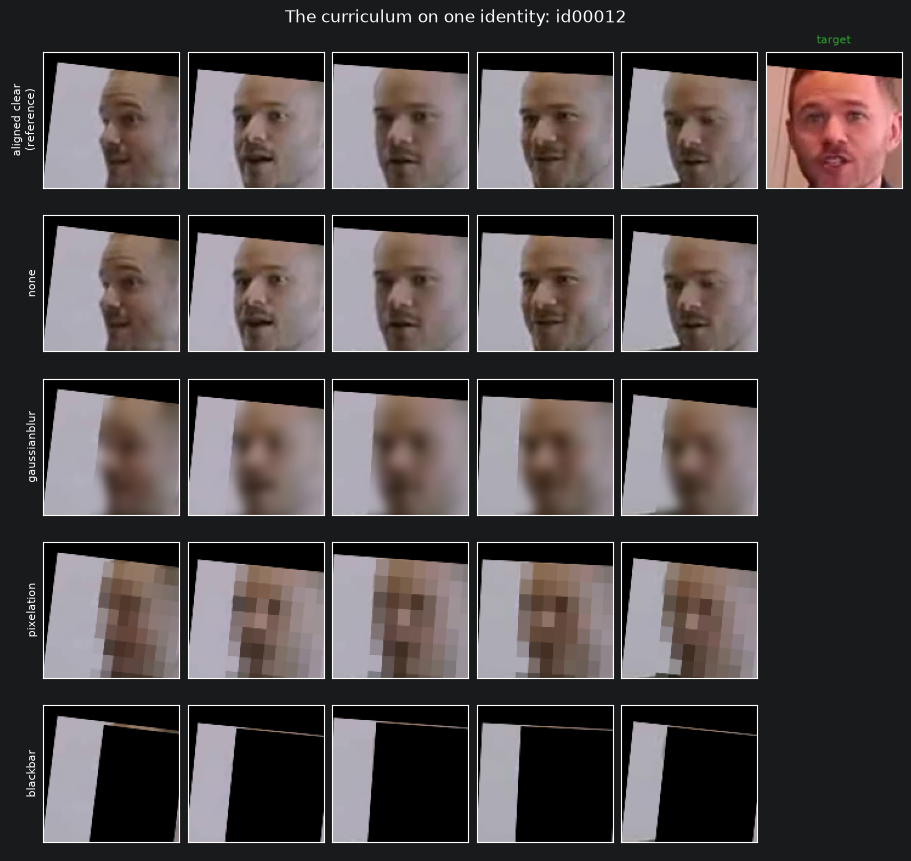

In [3]:
import cv2

# One batch, to confirm it is the shape Facial.forward takes. 'method' is the curriculum index
# every frame of that item was built with -- at stage 0 it is all zeros.
#
# num_workers=0 and not kept: this draws a single batch, and a worker-backed loader would leave
# forked copies of this process resident for the rest of the notebook.
inputs, target, method = next(iter(DataLoader(train_frames, batch_size=BATCH, shuffle=True)))
print(f"inputs {tuple(inputs.shape)} -> target {tuple(target.shape)}, method {tuple(method.shape)}")
print(f"range  [{inputs.min():.2f}, {inputs.max():.2f}]   methods in batch: {sorted(set(method.tolist()))}")

# One identity under every method in the curriculum, one column per frame. The top row is the
# clear alignment: if those faces are centred the geometry is right, and each row below is then
# that anonymization doing its job. Heavy anonymization alone looks a lot like a misaligned crop,
# which is why the clear row is here to compare against.
SHOWN = 5
identity = train_frames.identities[0]
paths = train_frames.pool[identity][:SHOWN]
rows = [(None, "aligned clear\n(reference)")] + [(i, name) for i, name in enumerate(train_frames.names)]

fig, axes = plt.subplots(len(rows), SHOWN + 1, figsize=(1.5 * (SHOWN + 1), 1.7 * len(rows)), layout="constrained")
for row, (method_index, label) in enumerate(rows):
    for column, path in enumerate(paths):
        crop = train_frames.crop(path, method_index, flip=False)
        axes[row, column].imshow(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB))
    axes[row, 0].set_ylabel(label, fontsize=8)
    axes[row, SHOWN].set_axis_off()

# The target, shown once against the clear row; the model only ever sees it as the thing to produce.
axes[0, SHOWN].set_axis_on()
axes[0, SHOWN].imshow(cv2.cvtColor(train_frames.crop(train_frames.target[identity], None, False), cv2.COLOR_BGR2RGB))
axes[0, SHOWN].set_title("target", fontsize=8, color="tab:green")

for ax in axes.flat:
    ax.set_xticks([])
    ax.set_yticks([])

fig.suptitle(f"The curriculum on one identity: {identity.replace('_', ' ')}", fontsize=12)
plt.show()

In [4]:
from meles.frame_aggregation.facial import Facial
from meles.frame_aggregation.pix2pix import to_image
from meles.frame_embedder import FrameEmbedder, models
from meles.training import (
    ContrastiveIdentityLoss, FacialTrainer, IdentityLoss, WeightedCriterion,
    identification, l1_per_item,
)

# Phase 1 only has to get the decoder and aggregator out of random; phase 2, with the encoder
# unfrozen, is where the result is actually made. Measured on the previous run: over its 12
# phase-2 epochs pixelation went 34.7% -> 60.5% and blackbar 2.4% -> 6.8%, and both were still
# climbing at the last epoch. So phase 2 gets its own, much larger budget.
EPOCHS = 60
EPOCHS_PHASE_2 = 60
# A clean-only run has a single stage, so it spends every epoch there rather than a quarter.
EPOCHS_PER_CURRICULUM_STAGE = EPOCHS if CLEAN_ONLY else EPOCHS // len(CURRICULUM)
STAGES = [0] if CLEAN_ONLY else None

# Named per loss, so a rerun lands beside the previous run instead of overwriting it.
# --- capacity -------------------------------------------------------------------------------
# Width was ruled out once before, on YouTube Faces: tripling the decoder moved rank-1 by 1.2
# points against ~5 points of epoch-to-epoch noise. That conclusion does not carry over. It was
# measured while the model was badly overfitting -- an 11x val/train gap on the identity loss --
# and a model that cannot use the data it has will not use more parameters either.
#
# On VoxCeleb2 the gaps are 1.0-1.1x across every loss term, which is underfitting, not
# overfitting. Capacity is a live hypothesis again for the first time, so test it.
#
# DROPOUT stays off for the same reason: it is a cure for overfitting and there is none to cure.
WIDTH = 2.0
DROPOUT = 0.0

# Named for the settings that change the result, so a sweep cannot overwrite itself. Width is in
# there because it changes the parameter shapes, and a checkpoint cannot be read without it.
# The corpus is in the name because it changes what rank-1 means: the gallery is every held-out
# identity, so YouTube Faces scored against 53 and VoxCeleb2 scores against ~575. A number from
# one is not comparable to the other. Existing 'facial.<scope>...' files keep their names and are
# simply not matched by this pattern -- nothing is overwritten.
SCOPE = "clean" if CLEAN_ONLY else "curriculum"
CHECKPOINT = f"models/facial.{CORPUS}.{SCOPE}.w{WIDTH:g}d{DROPOUT:g}.pt"

# 'methods' conditions the aggregator's pooling query on which anonymization the inputs carry.
model = Facial(
    weights="models/iresnet34.pth", methods=len(CURRICULUM), width=WIDTH, dropout=DROPOUT
).cuda()

decoder_parameters = sum(p.numel() for p in model.decoder.parameters())
print(f"decoder: {model.decoder.chans}, {decoder_parameters / 1e6:.2f} M parameters")

# --- the loss ------------------------------------------------------------------------------
# Three terms, each answering a different question:
#   l1           are these the right pixels?  Keeps the output a face at all. Kept, but given the
#                smallest share -- alone it produces the average face.
#   identity     is this the right person?    1 - cosine to the target under a frozen recogniser.
#   contrastive  this person *rather than*    InfoNCE over the batch. Cosine can rise towards
#                anyone else?                 everyone at once, which moves the distance and
#                                             leaves rank-1 where it was; only this ranks.
#
# Weights put the terms at comparable magnitudes given where the last run settled: l1 ~0.33,
# 1 - cos ~0.87, InfoNCE ~ln(BATCH) ~2.3 at chance. Identity now carries ~70% of the total where
# it carried 44%. A starting point, not tuned -- rank-1 below is what to tune them against.
critic = IdentityLoss(weights="models/iresnet34.pth")
criterion = WeightedCriterion({
    "l1": (1.0, l1_per_item),
    "identity": (1.0, critic),
    # Shares the critic's weights rather than loading a second copy of the same 137 MB network.
    "contrastive": (0.2, ContrastiveIdentityLoss(encoder=critic.encoder)),
})

# --- the metric ----------------------------------------------------------------------------
# ArcFace (w600k_r50) judges, never iresnet34: the critic grading its own work would only confirm
# that the loss went down. This is also the model the experiment itself scores with.
arcface = FrameEmbedder(models.ARCFACE)


ARCFACE_BATCH = 64  # images per ONNX Runtime call


def embed_arcface(images):
    """(B, 3, 112, 112) in [-1, 1] -> L2-normalised ArcFace embeddings."""
    # Straight through the session: the crops are already aligned, and re-detecting on a blurry
    # reconstruction would preprocess the probes differently from the gallery.
    #
    # Chunked, because 'identification' hands the whole gallery over in one call. ArcFace's first
    # PRelu activation is 64x112x112 floats per image -- 3.2 MB -- so 574 held-out identities ask
    # ONNX Runtime for a single 1.84 GB buffer and it refuses. YouTube Faces' 53 asked for 170 MB,
    # which is why this only appears on the larger corpus.
    blocks = []
    for start in range(0, len(images), ARCFACE_BATCH):
        crops = [to_image(image) for image in images[start:start + ARCFACE_BATCH]]
        blocks.append(np.asarray(arcface.session.run(arcface._blob(crops)), dtype=np.float64))
    vectors = np.concatenate(blocks)
    return vectors / np.linalg.norm(vectors, axis=1, keepdims=True)


def rank_metrics(trainer):
    """Rank-1/rank-5 identification, recorded into the history as 'val:rank1' etc."""
    return identification(trainer.model, validation_frames, embed_arcface)


# Divide by the ACTIVE methods, not the whole curriculum: 'all_methods' lays the validation set
# out as one item per (identity, active method), and under CLEAN_ONLY only one method is active.
# Dividing by len(CURRICULUM) reported 143 identities and 0.7% chance where it is 574 and 0.17%.
people = len(validation_frames) // len(validation_frames.active)
print(f"gallery: {people} held-out identities, chance rank-1 = {1 / people:.2%}")

/data/projects/personal/meles/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


decoder: (512, 384, 256, 128), 10.07 M parameters
gallery: 574 held-out identities, chance rank-1 = 0.17%


In [ ]:
# Phase 1: encoder frozen. The decoder and the aggregator are trained from scratch, so they get
# the full learning rate; the pretrained encoder is held still until they are no longer random.
trainer = FacialTrainer(model=model, methods=CURRICULUM, criterion=criterion, encoder_frozen=True)

history = trainer.fit(
    train_loader_for,
    validation_loader,
    epochs_per_stage=EPOCHS_PER_CURRICULUM_STAGE,
    stages=STAGES,
    checkpoint=CHECKPOINT,
    metrics=rank_metrics,
    # Rank-1 swings epoch to epoch -- ~5 points on YouTube Faces' 53-identity gallery, less on a
    # larger one. The last epoch is an arbitrary draw, so keep the best too, as CHECKPOINT.best.pt.
    best="val:rank1",
)

print(f"epoch {trainer.epoch}, stage {trainer.stage}")
for term in criterion.terms:
    print(f"  val {term:<12} {history[f'val:{term}'][-1]:.4f}")
print(f"\n  {'method':<14} {'rank-1':>8} {'rank-5':>8} {'1 - cos':>9}")
for name in validation_frames.active:
    print(f"  {name:<14} {history[f'val:rank1_{name}'][-1]:>7.1%} {history[f'val:rank5_{name}'][-1]:>8.1%} "
          f"{history[f'val:identity_{name}'][-1]:>9.4f}")
print(f"  {'overall':<14} {history['val:rank1'][-1]:>7.1%} {history['val:rank5'][-1]:>8.1%}")

stage 0 (none) epoch 1/15:  80%|████████  | 416/517 [01:41<00:24,  4.04it/s]

In [ ]:
# Phase 2: unfreeze the encoder and fine-tune it at a tenth of the rate. Only the final
# curriculum stage is re-run -- the data is already as hard as it gets, and what changes here is
# which parameters move, not what they see.
trainer.set_encoder_frozen(False)

history = trainer.fit(
    train_loader_for,
    validation_loader,
    epochs_per_stage=EPOCHS_PHASE_2,
    stages=[LAST_STAGE],
    checkpoint=CHECKPOINT,
    metrics=rank_metrics,
    # Rank-1 swings epoch to epoch -- ~5 points on YouTube Faces' 53-identity gallery, less on a
    # larger one. The last epoch is an arbitrary draw, so keep the best too, as CHECKPOINT.best.pt.
    best="val:rank1",
)

In [ ]:
# Four kinds of view, because each hides what the next one shows.
#   top-left     the total, per anonymization -- a rising total is equally consistent with
#                progress on a newly unlocked method and with forgetting an old one.
#   top-right    rank-1, the number the experiment scores. The one to steer on.
#   bottom row   every loss term, train against val. This is the memorisation detector: a term
#                whose train curve dives while its val curve stays flat is being memorised, not
#                learned, and no amount of further training will move the val side.
terms = [key.split(":", 1)[1] for key in history if key.startswith("val:") and "_" not in key.split(":", 1)[1]]
terms = [t for t in terms if not t.startswith("rank")]
scored = validation_frames.active
epochs = range(1, len(history["val"]) + 1)
stages = history["stage"]


def stage_bands(ax):
    bottom, top = ax.get_ylim()
    for stage in sorted(set(stages)):
        first = stages.index(stage)
        last = len(stages) - 1 - stages[::-1].index(stage)
        ax.axvspan(first + 0.5, last + 1.5, color="tab:grey", alpha=0.05 + 0.03 * stage, zorder=0)
        ax.text(
            (first + last) / 2 + 1, bottom, f" stage {int(stage)} ",
            ha="center", va="bottom", fontsize=8, color="dimgrey",
        )
    ax.set_ylim(bottom, top)


columns = max(2, len(terms))
fig, axes = plt.subplots(2, columns, figsize=(5.4 * columns, 9.0), squeeze=False, layout="constrained")
for ax in axes.flat:
    ax.set_axis_off()

ax = axes[0, 0]
ax.set_axis_on()
ax.plot(epochs, history["val"], color="black", linewidth=2, label="val", zorder=5)
ax.plot(epochs, history["train"], color="black", linestyle=":", linewidth=1.4, label="train")
for name in scored:
    ax.plot(epochs, history[f"val_{name}"], linewidth=1.2, alpha=0.8, label=f"val {name}")
ax.set_title("Total weighted loss")
ax.set_ylabel("loss")

if "val:rank1" in history:
    ax = axes[0, 1]
    ax.set_axis_on()
    ax.plot(epochs, history["val:rank1"], color="black", linewidth=2, label="all", zorder=5)
    for name in scored:
        ax.plot(epochs, history[f"val:rank1_{name}"], linewidth=1.4, label=name)
    ax.axhline(1 / people, color="tab:red", linestyle="--", linewidth=1, label="chance")
    ax.set_title(f"Rank-1 identification (ArcFace, {people} identities)")
    ax.set_ylabel("rank-1")
    ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")

# One panel per loss term, train against val.
for column, term in enumerate(terms):
    ax = axes[1, column]
    ax.set_axis_on()
    ax.plot(epochs, history[f"val:{term}"], color="tab:blue", linewidth=2, label="val")
    ax.plot(epochs, history[f"train:{term}"], color="tab:orange", linestyle=":", linewidth=1.8, label="train")
    gap = history[f"val:{term}"][-1] - history[f"train:{term}"][-1]
    ax.set_title(f"{term}  (val - train = {gap:+.3f})")
    ax.set_ylabel(f"{term} (weighted)")

for ax in axes.flat:
    if not ax.get_visible() or not ax.has_data():
        continue
    ax.set_xlabel("epoch")
    ax.legend(ncols=2, fontsize=8, loc="best")
    ax.grid(alpha=0.3)
    stage_bands(ax)

plt.show()

## Storing the model, and looking at what it produces

`fit(checkpoint=...)` already wrote `CHECKPOINT` after **every** epoch, so the trained model is
on disk — paths are relative to this notebook, i.e. under `src/notebooks/models/`. The cell below
reloads it from scratch (no trainer needed) and reconstructs held-out faces.

- `trainer.save(path)` writes a resumable checkpoint: weights, optimiser state, epoch, stage and
  the full history.
- `trainer.save(path, inference_only=True)` drops the optimiser, which is roughly two thirds of
  the file — AdamW keeps two moment estimates per parameter. The result can be run but not resumed.
- `load_facial(path)` gives back `(model, metadata)` for inference without building a trainer.
- `trainer.load(path)` restores a run, including which encoder phase it was in.

In [ ]:
from meles.frame_aggregation.pix2pix import to_image
from meles.training.facial import load_facial, reconstruct

# A smaller export for inference: same weights, no optimiser state.
trainer.save(CHECKPOINT.replace(".pt", ".inference.pt"), inference_only=True)

# Reload from disk, so this cell works in a fresh kernel without retraining.
loaded, meta = load_facial(CHECKPOINT)
print(f"epoch {meta['epoch']}, stage {meta['stage']}, methods {meta['methods']}")

SHOWN = 6
# 'all_methods' lays the split out as identity-major blocks, one entry per *active* method -- one
# of them in a clean-only run, four in a full curriculum.
scored = validation_frames.active
width = len(scored)

fig, axes = plt.subplots(width + 2, SHOWN, figsize=(1.55 * SHOWN, 1.75 * (width + 2)), squeeze=False, layout="constrained")
for ax in axes.flat:
    ax.set_xticks([])
    ax.set_yticks([])

for column in range(SHOWN):
    identity = validation_frames.identities[column]

    # Item 'column * width + i' is this identity under scored[i], on the same frames.
    observations, target, _ = validation_frames[column * width]
    axes[0, column].imshow(cv2.cvtColor(to_image(observations[0]), cv2.COLOR_BGR2RGB))
    axes[0, column].set_title(identity.replace("_", " ")[:18], fontsize=7)
    axes[1, column].imshow(cv2.cvtColor(to_image(target), cv2.COLOR_BGR2RGB))

    for index in range(width):
        anonymized, _, method = validation_frames[column * width + index]
        produced = reconstruct(loaded, anonymized, int(method))[0]
        axes[2 + index, column].imshow(cv2.cvtColor(to_image(produced), cv2.COLOR_BGR2RGB))

axes[0, 0].set_ylabel(f"one input\n({scored[0]})", fontsize=7)
axes[1, 0].set_ylabel("target", fontsize=7, color="tab:green")
for index, name in enumerate(scored):
    axes[2 + index, 0].set_ylabel(f"recon\n{name}", fontsize=7)

fig.suptitle(f"Reconstructions on held-out identities (epoch {meta['epoch']})", fontsize=12)
plt.show()

## Does observation diversity explain the result?

The premise is that aggregating **many** frames recovers what one does not. But a YouTube Faces
video is only ~3 seconds, and frames within one sit at 0.78 mean cosine against 0.42 across
videos — so what an item really holds is not eight observations, it is however many *videos* it
spans. After the target's video is excluded that is 1.8 on average, and for 47% of identities it
is exactly one.

This cell splits the validation identities by how many videos they had to offer. It costs one
forward pass and needs no extra training, and it separates three explanations that the headline
rank-1 confounds: too few identities, too little model, or too few independent observations.

If rank-1 rises with the number of available videos, the premise is working and the dataset is
what limits it.

In [ ]:
# Rank-1 per validation identity, grouped by how many videos that identity could draw from.
import numpy as np

people = len(validation_frames) // len(validation_frames.active)
gallery = embed_arcface(torch.stack([validation_frames[i * len(validation_frames.active)][1]
                                     for i in range(people)]))

produced = []
for begin in range(0, people, 16):
    block = torch.stack([validation_frames[p * len(validation_frames.active)][0]
                         for p in range(begin, min(begin + 16, people))])
    produced.append(reconstruct(loaded, block, 0))
hit = (embed_arcface(torch.cat(produced)) @ gallery.T).argmax(axis=1) == np.arange(people)

videos = np.array([len(validation_frames.videos[i]) for i in validation_frames.identities])
print(f"{people} validation identities, rank-1 overall {hit.mean():.1%}  "
      f"(chance {1 / people:.1%})\n")
print("  videos available | identities | rank-1")
print("  -----------------+------------+-------")
for count in sorted(set(videos)):
    mask = videos == count
    print(f"  {count:>16} | {mask.sum():>10} | {hit[mask].mean():>5.1%}")

one, many = hit[videos == 1], hit[videos >= 2]
if len(one) and len(many):
    error = np.sqrt(one.var() / len(one) + many.var() / len(many))
    print(f"\n  one video  {one.mean():.1%} (n={len(one)})")
    print(f"  2+ videos  {many.mean():.1%} (n={len(many)})")
    print(f"  difference {many.mean() - one.mean():+.1%}, about {abs(many.mean() - one.mean()) / max(error, 1e-9):.1f} "
          f"standard errors")